# 19 Question Answering Span

Mencari potongan jawaban di dalam teks. Contoh: dataset FacQA, pertanyaan faktual bahasa Indonesia.

**Daftar isi**

1. Kartu Masalah
2. Kapan Pakai Notebook Ini
3. Config
4. EDA
5. Preprocessing
6. Validasi
7. Baseline
8. Model Utama
9. Post-processing
10. Post-analysis
11. Keluaran

## 1. Kartu Masalah

| Bagian | Isi |
|---|---|
| **Task** | Menjawab pertanyaan dengan mengambil potongan teks |
| **Unit prediksi** | Satu pasangan pertanyaan dan teks mendapat satu span |
| **Metrik** | Exact match dan F1 token |
| **Masalah terbesar** | Argmax per token bisa menghasilkan jawaban yang terpecah: exact match hanya 0,5177 sebelum post-processing. |
| **Data contoh** | FacQA: 2.495 latih, 311 valid, 311 test |

## 2. Kapan Pakai Notebook Ini

**Pakai kalau** soal memberi pertanyaan dan teks, dan jawabannya berupa potongan teks tersebut. Metriknya
biasanya exact match dan F1 token.

**Yang perlu diganti kalau datanya beda:**
- `read_split`, kalau jawaban disimpan sebagai posisi karakter dan bukan label BIO.
- `MODEL_RUNS` di config.
- Jawaban yang tidak ada di teks butuh penanganan khusus, misalnya threshold kosong.

## 3. Config

**Import dan lingkungan.** Mode offline dinyalakan di sini, dan progress bar serta warning
dimatikan supaya output tetap bersih.

In [1]:
import importlib.util
import json
import os
import random
import subprocess
import sys
import time
import warnings
from contextlib import contextmanager
from pathlib import Path

os.environ.update(
    CUDA_VISIBLE_DEVICES="0",
    HF_HUB_OFFLINE="1",
    TRANSFORMERS_OFFLINE="1",
    TOKENIZERS_PARALLELISM="false",
    TQDM_DISABLE="1",
    PYTHONWARNINGS="ignore",
    HF_HUB_DISABLE_PROGRESS_BARS="1",
)
warnings.filterwarnings("ignore")
sys.modules["tensorflow"] = None  # tidak dipakai; mencegah log TensorFlow saat umap diimpor

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
import torch  # noqa: E402
from transformers.utils import logging as hf_logging  # noqa: E402

hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
pd.set_option("display.max_colwidth", 90, "display.max_rows", 30, "display.width", 140)
plt.rcParams.update(
    {
        "figure.figsize": (8, 3.5),
        "figure.dpi": 90,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
print(f"device={DEVICE} | torch={torch.__version__}")

device=cuda | torch=2.11.0+cu130


**Lokasi file.** `find_pack` mencari paket offline, dan `find_file` mencari file data di Kaggle
atau folder lokal. Di mesin lokal, set `PACK_DIR` dan `DATA_ROOT` lewat environment variable.

In [2]:
INPUT_ROOTS = [Path(p) for p in (os.environ.get("DATA_ROOT"), "/kaggle/input", ".") if p]


def find_pack() -> Path:
    """Cari folder paket offline lewat file pack_manifest.json."""
    if os.environ.get("PACK_DIR"):
        return Path(os.environ["PACK_DIR"])
    for root in INPUT_ROOTS:
        for manifest in root.glob("**/pack_manifest.json"):
            return manifest.parent
    raise FileNotFoundError("Paket offline tidak ketemu. Set environment variable PACK_DIR.")


def find_file(name: str) -> Path:
    """Cari file data berdasarkan nama di semua folder input."""
    for root in INPUT_ROOTS:
        for path in root.glob(f"**/{name}"):
            return path
    raise FileNotFoundError(f"File {name} tidak ketemu di {INPUT_ROOTS}")


def install_offline(*modules: str) -> None:
    """Pasang library dari wheel paket offline, hanya bila belum terpasang."""
    missing = [m for m in modules if importlib.util.find_spec(m.replace("-", "_")) is None]
    if missing:
        subprocess.run(
            [
                sys.executable,
                "-m",
                "pip",
                "install",
                "-q",
                "--no-index",
                "--find-links",
                str(PACK_DIR / "wheels"),
                "--root-user-action=ignore",
                *missing,
            ],
            check=True,
        )


PACK_DIR = find_pack()
MODEL_DIR = PACK_DIR / "models"
EXTRA_DATA_DIR = PACK_DIR / "data"
RESULT_DIR = Path("hasil")
RESULT_DIR.mkdir(exist_ok=True)
print(f"paket offline: {PACK_DIR}")

paket offline: /kaggle/input/notebooks/ivanwllm/gemastik-nlp-00-setup-offline


**Pencatat waktu dan ringkasan.** `stage` mencatat durasi tiap tahap, dan `run_summary` mencetak
ringkasan akhir yang dibaca skrip audit.

In [3]:
RUN_START = time.time()
STAGE_SECONDS: dict[str, float] = {}


@contextmanager
def stage(name: str):
    """Catat durasi satu tahap."""
    start = time.time()
    yield
    STAGE_SECONDS[name] = round(time.time() - start, 1)
    print(f"[waktu] {name}: {STAGE_SECONDS[name]:.0f} detik")


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def run_summary(task: str, n_rows: int, metrics: dict, needs_gpu: bool = True) -> None:
    """Simpan dan cetak ringkasan run."""
    total = int(time.time() - RUN_START)
    used_gpu = torch.cuda.is_available() and torch.cuda.max_memory_allocated() > 0
    summary = {
        "task": task,
        "mode": MODE,
        "use_pretrained": USE_PRETRAINED,
        "n_rows": n_rows,
        "total_detik": total,
        "gpu": used_gpu,
        "tahap_detik": STAGE_SECONDS,
        "metrik": metrics,
    }
    (RESULT_DIR / "ringkasan.json").write_text(json.dumps(summary, indent=1))
    note = "" if needs_gpu else " gpu_tidak_wajib"
    print(
        f"RINGKASAN_RUN task={task} mode={MODE} n_rows={n_rows} total_detik={total} "
        f"gpu={used_gpu}{note}"
    )
    print(json.dumps(metrics, indent=1))

**Pengaturan utama.** Semua yang perlu diubah ada di sel ini.

In [4]:
MODE = "penuh"  # "cepat" (<30 menit) atau "penuh" (<2 jam)
USE_PRETRAINED = True  # False: hanya baseline kemiripan kata, tanpa file model dari luar
SEED = 42
N_ROWS = 5000
MAX_LEN = 192

SETTINGS = {
    "cepat": {"epochs": 3, "model_runs": [("indobert", SEED)]},
    "penuh": {
        "epochs": 6,
        "model_runs": [("indobert", SEED), ("indobert", SEED + 1), ("indobert", SEED + 2)],
    },
}[MODE]

seed_everything(SEED)
print(SETTINGS)

{'epochs': 6, 'model_runs': [('indobert', 42), ('indobert', 43), ('indobert', 44)]}


## 4. EDA

Muat data. Pertanyaan, teks, dan label tersimpan sebagai string berbentuk daftar Python.

In [5]:
import ast  # noqa: E402
from collections import Counter  # noqa: E402

from transformers import AutoModelForTokenClassification, AutoTokenizer  # noqa: E402
from transformers import get_linear_schedule_with_warmup  # noqa: E402


def read_split(split: str) -> pd.DataFrame:
    path = EXTRA_DATA_DIR / "indonlu/dataset/facqa_qa-factoid-itb" / f"{split}_preprocess.csv"
    frame = pd.read_csv(path).head(N_ROWS)
    for col in ("question", "passage", "seq_label"):
        frame[col] = frame[col].map(ast.literal_eval)
    return frame


def answer_tokens(tokens: list[str], tags: list[str]) -> list[str]:
    """Ambil token berlabel selain O sebagai jawaban."""
    return [t for t, tag in zip(tokens, tags) if tag != "O"]


train, valid, test = read_split("train"), read_split("valid"), read_split("test")
for frame in (train, valid, test):
    frame["answer"] = [answer_tokens(p, s) for p, s in zip(frame["passage"], frame["seq_label"])]
print(f"latih={len(train)} | valid={len(valid)} | test={len(test)}")
print("pertanyaan:", " ".join(train["question"][0]))
print("jawaban:", " ".join(train["answer"][0]))

latih=2495 | valid=311 | test=311
pertanyaan: Kelompok apakah yang menyatakan bertanggung jawab atas ledakan di Srinagar ?
jawaban: Hezb-ul Mujahedeen


Panjang teks dan jawaban, serta kata tanya yang paling sering.

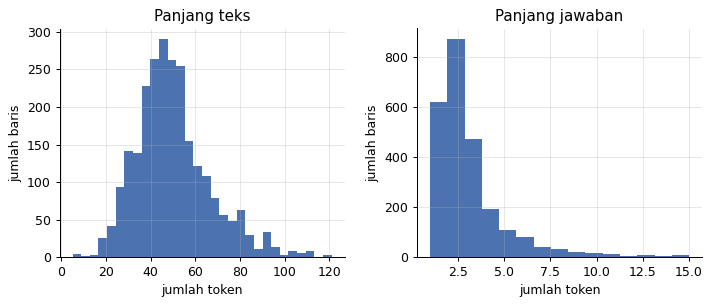

kata pertama pertanyaan: [('siapakah', 325), ('apa', 233), ('berapa', 212), ('apakah', 186), ('berapakah', 153), ('siapa', 142)]
jawaban kosong: 0
teks lebih panjang dari batas: 0.0


In [6]:
fig, axes = plt.subplots(1, 2)
train["passage"].str.len().plot.hist(bins=30, ax=axes[0], color="#4C72B0")
axes[0].set(title="Panjang teks", xlabel="jumlah token", ylabel="jumlah baris")
train["answer"].str.len().clip(upper=15).plot.hist(bins=15, ax=axes[1], color="#4C72B0")
axes[1].set(title="Panjang jawaban", xlabel="jumlah token", ylabel="jumlah baris")
plt.tight_layout()
plt.show()
print("kata pertama pertanyaan:", Counter(q[0].lower() for q in train["question"]).most_common(6))
print("jawaban kosong:", int((train["answer"].str.len() == 0).sum()))
print(
    "teks lebih panjang dari batas:", round((train["passage"].str.len() > MAX_LEN - 30).mean(), 3)
)

**Temuan dan keputusan**

| Temuan | Keputusan |
|---|---|
| Tidak ada jawaban kosong | Tidak perlu kelas tidak ada jawaban. Kalau soal punya, tambahkan |
| Tidak ada teks melebihi batas | Tidak perlu sliding window |
| Kata tanya beragam | Laporkan skor per kata tanya |

## 5. Preprocessing

Data sudah berupa token. Pertanyaan dan teks digabung sebagai dua segmen. Label hanya ditaruh pada token
pertama tiap kata di segmen teks, sisanya -100 supaya diabaikan oleh loss.

In [7]:
LABELS = ["O", "B", "I"]
LABEL_TO_ID = {name: i for i, name in enumerate(LABELS)}


def normalize_tag(tag: str) -> str:
    return tag[0] if tag != "O" else "O"


def encode(tokenizer, frame: pd.DataFrame, with_labels: bool = True):
    encoded = tokenizer(
        frame["question"].tolist(),
        frame["passage"].tolist(),
        is_split_into_words=True,
        truncation="only_second",
        max_length=MAX_LEN,
        padding="max_length",
        return_tensors="pt",
    )
    if not with_labels:
        return encoded, None
    labels = np.full(encoded["input_ids"].shape, -100)
    for row, tags in enumerate(frame["seq_label"]):
        previous = None
        for col, (word, segment) in enumerate(
            zip(encoded.word_ids(row), encoded.sequence_ids(row))
        ):
            if segment == 1 and word is not None and word != previous:
                labels[row, col] = LABEL_TO_ID[normalize_tag(tags[word])]
            previous = word if segment == 1 else None
    return encoded, torch.tensor(labels)

## 6. Validasi

Memakai split yang disediakan: valid untuk memilih, test hanya untuk laporan. Ada dua metrik: exact match dan
F1 token, karena jawaban yang hampir benar tetap punya nilai.

In [8]:
def token_f1(pred: list[str], gold: list[str]) -> float:
    common = sum((Counter(t.lower() for t in pred) & Counter(t.lower() for t in gold)).values())
    if not pred or not gold or not common:
        return float(pred == gold)
    precision, recall = common / len(pred), common / len(gold)
    return 2 * precision * recall / (precision + recall)


def qa_scores(preds: list[list[str]], golds: list[list[str]]) -> dict[str, float]:
    exact = np.mean(
        [[t.lower() for t in p] == [t.lower() for t in g] for p, g in zip(preds, golds)]
    )
    f1 = np.mean([token_f1(p, g) for p, g in zip(preds, golds)])
    return {"exact": round(float(exact), 4), "f1": round(float(f1), 4)}


assert qa_scores([["Jakarta"]], [["jakarta"]]) == {"exact": 1.0, "f1": 1.0}
assert abs(token_f1(["a", "b"], ["a"]) - 2 / 3) < 1e-9
results: list[dict] = []


def record(name: str, pred_valid, pred_test) -> None:
    valid_scores = qa_scores(pred_valid, valid["answer"].tolist())
    test_scores = qa_scores(pred_test, test["answer"].tolist())
    results.append(
        {
            "model": name,
            "f1_valid": valid_scores["f1"],
            "exact_valid": valid_scores["exact"],
            "f1_test": test_scores["f1"],
            "exact_test": test_scores["exact"],
        }
    )
    print(results[-1])

## 7. Baseline

Pilih jendela kata di teks yang tetangganya paling banyak berbagi kata dengan pertanyaan, dan yang isinya
belum ada di pertanyaan. Tidak butuh pelatihan.

In [9]:
def overlap_baseline(
    question: list[str], passage: list[str], window: int = 3, context: int = 6
) -> list[str]:
    query = {w.lower() for w in question}
    best_score, best_start = -1, 0
    for start in range(len(passage) - window + 1):
        around = (
            passage[max(0, start - context) : start]
            + passage[start + window : start + window + context]
        )
        inside = passage[start : start + window]
        new_words = sum(w.lower() not in query and w[0].isupper() for w in inside)
        score = sum(w.lower() in query for w in around) + 0.5 * new_words
        if score > best_score:
            best_score, best_start = score, start
    return passage[best_start : best_start + window]


record(
    "kemiripan_kata",
    [overlap_baseline(q, p) for q, p in zip(valid["question"], valid["passage"])],
    [overlap_baseline(q, p) for q, p in zip(test["question"], test["passage"])],
)

{'model': 'kemiripan_kata', 'f1_valid': 0.2513, 'exact_valid': 0.045, 'f1_test': 0.2422, 'exact_test': 0.0354}


## 8. Model Utama

Label token pada segmen teks dengan IndoBERT. Probabilitas tiap seed dirata-rata per kata sebelum diambil
span terbaiknya.

In [10]:
def train_model(model_name: str, epochs: int, seed: int, batch_size: int = 16):
    seed_everything(seed)
    tokenizer = AutoTokenizer.from_pretrained(MODEL_DIR / model_name)
    model = AutoModelForTokenClassification.from_pretrained(
        MODEL_DIR / model_name, num_labels=len(LABELS)
    ).to(DEVICE)
    encoded, target = encode(tokenizer, train)
    optimizer = torch.optim.AdamW(model.parameters(), lr=3e-5, weight_decay=0.01)
    steps = epochs * (len(train) // batch_size + 1)
    scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * steps), steps)
    scaler = torch.amp.GradScaler("cuda", enabled=DEVICE == "cuda")
    generator = np.random.default_rng(seed)
    model.train()
    for _ in range(epochs):
        order = generator.permutation(len(train))
        for start in range(0, len(order), batch_size):
            pick = torch.as_tensor(order[start : start + batch_size])
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast("cuda", enabled=DEVICE == "cuda"):
                loss = model(
                    input_ids=encoded["input_ids"][pick].to(DEVICE),
                    attention_mask=encoded["attention_mask"][pick].to(DEVICE),
                    labels=target[pick].to(DEVICE),
                ).loss
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
    return tokenizer, model


@torch.inference_mode()
def word_probs(model, tokenizer, frame: pd.DataFrame, batch_size: int = 32) -> list[np.ndarray]:
    """Probabilitas label per kata teks. Kata yang terpotong diberi O."""
    model.eval()
    encoded, _ = encode(tokenizer, frame, with_labels=False)
    output = []
    for start in range(0, len(frame), batch_size):
        ids = encoded["input_ids"][start : start + batch_size].to(DEVICE)
        mask = encoded["attention_mask"][start : start + batch_size].to(DEVICE)
        with torch.autocast("cuda", enabled=DEVICE == "cuda"):
            probs = (
                torch.softmax(model(input_ids=ids, attention_mask=mask).logits.float(), -1)
                .cpu()
                .numpy()
            )
        for row in range(len(ids)):
            index = start + row
            passage = frame["passage"].iloc[index]
            word_prob = np.tile(np.array([1.0, 0.0, 0.0]), (len(passage), 1))
            previous = None
            for col, (word, segment) in enumerate(
                zip(encoded.word_ids(index), encoded.sequence_ids(index))
            ):
                if segment == 1 and word is not None and word != previous:
                    word_prob[word] = probs[row, col]
                previous = word if segment == 1 else None
            output.append(word_prob)
    return output


probs_valid = [np.zeros((len(p), 3)) for p in valid["passage"]]
probs_test = [np.zeros((len(p), 3)) for p in test["passage"]]
with stage("transformer"):
    if USE_PRETRAINED:
        for model_name, seed in SETTINGS["model_runs"]:
            tokenizer, model = train_model(model_name, SETTINGS["epochs"], seed)
            for store, frame in ((probs_valid, valid), (probs_test, test)):
                for i, value in enumerate(word_probs(model, tokenizer, frame)):
                    store[i] += value / len(SETTINGS["model_runs"])
            del model
            torch.cuda.empty_cache()

[waktu] transformer: 512 detik


Label dengan probabilitas tertinggi per kata, tanpa aturan tambahan.

In [11]:
def decode_argmax(prob: np.ndarray, passage: list[str]) -> list[str]:
    return [w for w, label in zip(passage, prob.argmax(1)) if label != 0]


if USE_PRETRAINED:
    record(
        "model_utama_argmax",
        [decode_argmax(a, p) for a, p in zip(probs_valid, valid["passage"])],
        [decode_argmax(a, p) for a, p in zip(probs_test, test["passage"])],
    )

{'model': 'model_utama_argmax', 'f1_valid': 0.7293, 'exact_valid': 0.5305, 'f1_test': 0.7326, 'exact_test': 0.5177}


## 9. Post-processing

Pertanyaan faktual biasanya punya satu jawaban. Jadi dipilih **satu span terbaik**: mulai dari B dan lanjut I.
Hasilnya selalu berupa potongan utuh dan tidak pernah kosong.

In [12]:
def best_span(prob: np.ndarray, passage: list[str], max_words: int = 12) -> list[str]:
    """Pilih span dengan peluang gabungan tertinggi.

    Skor tiap kata dihitung relatif terhadap label O: kata di luar span berlabel O, jadi yang menentukan
    adalah selisih log peluang B atau I dengan O. Tanpa selisih ini, span panjang selalu kalah.
    """
    logs = np.log(prob + 1e-9)
    begin_gain, inside_gain = logs[:, 1] - logs[:, 0], logs[:, 2] - logs[:, 0]
    best_score, best = -np.inf, (0, 1)
    for start in range(len(passage)):
        score = begin_gain[start]
        for end in range(start + 1, min(start + max_words, len(passage)) + 1):
            if score > best_score:
                best_score, best = score, (start, end)
            if end < len(passage):
                score += inside_gain[end]
    return passage[best[0] : best[1]]


_toy_prob = np.array([[0.9, 0.05, 0.05], [0.1, 0.8, 0.1], [0.1, 0.1, 0.8], [0.9, 0.05, 0.05]])
assert best_span(_toy_prob, ["a", "b", "c", "d"]) == ["b", "c"]


if USE_PRETRAINED:
    final_valid = [best_span(a, p) for a, p in zip(probs_valid, valid["passage"])]
    final_test = [best_span(a, p) for a, p in zip(probs_test, test["passage"])]
    record("model_utama_span_terbaik", final_valid, final_test)
else:
    final_valid = [overlap_baseline(q, p) for q, p in zip(valid["question"], valid["passage"])]
    final_test = [overlap_baseline(q, p) for q, p in zip(test["question"], test["passage"])]

{'model': 'model_utama_span_terbaik', 'f1_valid': 0.7841, 'exact_valid': 0.6399, 'f1_test': 0.7725, 'exact_test': 0.6013}


## 10. Post-analysis

**Tabel perbandingan.**

In [13]:
result_table = pd.DataFrame(results)
result_table.to_csv(RESULT_DIR / "perbandingan.csv", index=False)
result_table

,model,f1_valid,exact_valid,f1_test,exact_test
0,kemiripan_kata,0.2513,0.0450,0.2422,0.0354
1,model_utama_argmax,0.7293,0.5305,0.7326,0.5177
2,model_utama_span_terbaik,0.7841,0.6399,0.7725,0.6013


**Skor per kata tanya.** Pertanyaan `siapa` dan `berapa` biasanya lebih mudah daripada `apa`.

In [14]:
per_word = pd.DataFrame(
    {
        "kata_tanya": [
            next(
                (
                    w.lower()
                    for w in q
                    if w.lower()
                    in {"siapa", "apa", "apakah", "berapa", "kapan", "dimana", "di", "mana"}
                ),
                "lain",
            )
            for q in test["question"]
        ],
        "f1": [token_f1(p, g) for p, g in zip(final_test, test["answer"])],
    }
)
per_word.groupby("kata_tanya")["f1"].agg(["size", "mean"]).round(3).sort_values(
    "size", ascending=False
)

,size,mean
kata_tanya,,
lain,99,0.781
apakah,58,0.716
di,43,0.823
apa,39,0.765
berapa,34,0.728
kapan,19,0.811
siapa,15,0.869
dimana,3,0.980
mana,1,0.000


**Contoh jawaban salah.**

In [15]:
rows = []
for question, gold, pred in zip(test["question"], test["answer"], final_test):
    if token_f1(pred, gold) < 1:
        rows.append(
            {
                "pertanyaan": " ".join(question)[:70],
                "asli": " ".join(gold)[:40],
                "prediksi": " ".join(pred)[:40],
            }
        )
    if len(rows) == 8:
        break
pd.DataFrame(rows)

,pertanyaan,asli,prediksi
0,Apakah nama penghargaan yang diterima Sejarawan Sartono Kartodirdjo da,Penghargaan Achmad Bakrie 2005,Penghargaan Khusus Achmad Bakrie 2005
1,Kanselir Gerhard Schroeder berasal dari negara mana ?,Jerman,Berlin
2,Apakah nama program yang dilakukan Dinas Kehutanan Sulsel dalam upaya,Gerakan Rehabilitasi Hutan,22.000
3,Apa nama perusahaan yang memperoleh izin untuk membangun Bandara Kuala,PT Angkasa Pura,PT Angkasa Pura II
4,Dimanakah lokasi sumber panas bumi di Jabar yang berkapasitas 330 MW ?,Awibengkok Gunung Salak,Gunung Salak
5,Apa nama negara peserta patroli udara Selat Malaka ?,"Indonesia , Malaysia , Singapura , dan T",Malaysia
6,Berapa angka pengangguran di Indonesia pada tahun 2005 ?,"10,9 juta jiwa 10,3 persen dari jumlah p","105,8 juta jiwa"
7,Apakah nama RSUP di Medan ?,RSUP Adam Malik,Adam Malik


## 11. Keluaran

File untuk dikumpulkan dan ringkasan run.

In [16]:
pd.DataFrame({"id": range(len(final_test)), "jawaban": [" ".join(p) for p in final_test]}).to_csv(
    RESULT_DIR / "submission.csv", index=False
)
run_summary(
    "qa_span",
    len(train),
    {r["model"]: {"f1_test": r["f1_test"], "exact_test": r["exact_test"]} for r in results},
    needs_gpu=USE_PRETRAINED,
)

RINGKASAN_RUN task=qa_span mode=penuh n_rows=2495 total_detik=524 gpu=True
{
 "kemiripan_kata": {
  "f1_test": 0.2422,
  "exact_test": 0.0354
 },
 "model_utama_argmax": {
  "f1_test": 0.7326,
  "exact_test": 0.5177
 },
 "model_utama_span_terbaik": {
  "f1_test": 0.7725,
  "exact_test": 0.6013
 }
}


**Poin untuk presentasi**

- F1 test 0,7725 dan exact 0,6013, sedangkan baseline kemiripan kata hanya 0,2422.
- Memilih span terbaik menaikkan exact match dari 0,5177 ke 0,6013 tanpa melatih ulang.
- Pertanyaan `siapa` lebih mudah (0,869), dan `apakah` lebih sulit (0,716).